# k-fold cross-validation

One train/test split can be lucky or unlucky. **Cross-validation** scores a model on every part of the data, one part at a time, and gives you a mean and a spread.

This notebook goes with the **k-fold cross-validation** lesson on [ML Visual](https://mohammad-qt.github.io/ML_DL_Vis/). Run each cell in order with **Shift + Enter**. Nothing to install: Colab already has every library used here.

## 1. Load the data

Each row is a tumour sample from a breast biopsy. The columns are eight measurements of the cell nuclei (size, texture, shape). The goal: predict whether the sample is **malignant** (`diagnosis = 1`) or **benign** (`0`).

The data is the Breast Cancer Wisconsin (Diagnostic) data set from the UCI repository (CC BY 4.0), reduced to eight columns. This is a teaching example, not medical advice.

In [1]:
import numpy as np
import pandas as pd

# The data lives in this project's GitHub repository, so there is nothing to upload.
DATA_URL = "https://raw.githubusercontent.com/Mohammad-QT/ML_DL_Vis/main/datasets/breast_cancer.csv"
dataset = pd.read_csv(DATA_URL)
X = dataset.drop(columns="diagnosis")
y = dataset["diagnosis"]
print(dataset.shape)
dataset.head()

(569, 9)


,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430


## 2. One split is one opinion

We train the same model on five different random splits. Watch how much the test score moves.

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

# The scaler lives inside the pipeline, so each fold fits it on its own training part only.
model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

for seed in range(5):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=seed)
    print(f"split {seed}: test accuracy {model.fit(X_train, y_train).score(X_test, y_test):.3f}")

split 0: test accuracy 0.909
split 1: test accuracy 0.916
split 2: test accuracy 0.923
split 3: test accuracy 0.930
split 4: test accuracy 0.923


## 3. k-fold cross-validation

`KFold` cuts the rows into `n_splits` folds. `cross_val_score` trains one model per fold and returns the score of each held-out fold. `shuffle=True` mixes the rows first, and `random_state` makes the shuffle repeatable.

In [3]:
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=0)
scores = cross_val_score(model, X, y, cv=cv)
print("fold scores:", scores.round(3))
print(f"mean {scores.mean():.3f} +/- {scores.std():.3f}")

fold scores: [0.904 0.93  0.947 0.93  0.947]
mean 0.931 +/- 0.016


## 4. Compare models fairly

With the same folds, a cross-validated score is a fair way to compare two models.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

candidates = {
    "K-NN (k=5)": model,
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=0),
}
for name, m in candidates.items():
    s = cross_val_score(m, X, y, cv=cv)
    print(f"{name:26s} {s.mean():.3f} +/- {s.std():.3f}")

K-NN (k=5)                 0.931 +/- 0.016
Logistic regression        0.940 +/- 0.022


Decision tree (depth 4)    0.924 +/- 0.019


## 5. Try it yourself

- Change `n_splits` to 3 and to 10. What happens to the spread?
- Try `StratifiedKFold` from `sklearn.model_selection`. It keeps the share of each class the same in every fold.
- Remember: cross-validation only **measures**. Train your final model once on all the data.

## See it: one split versus k folds

**Left:** the score of each of the 5 folds, with the mean (solid line) and mean ± standard deviation (shaded band). **Right:** the test score of 5 single random splits, drawn the same way. **Notice how** every bar is a different number, so which split you happen to pick changes the answer. Cross-validation tests on every row exactly once and reports a mean with a spread, which is a fairer summary than any one split. (The vertical axis is zoomed in.)

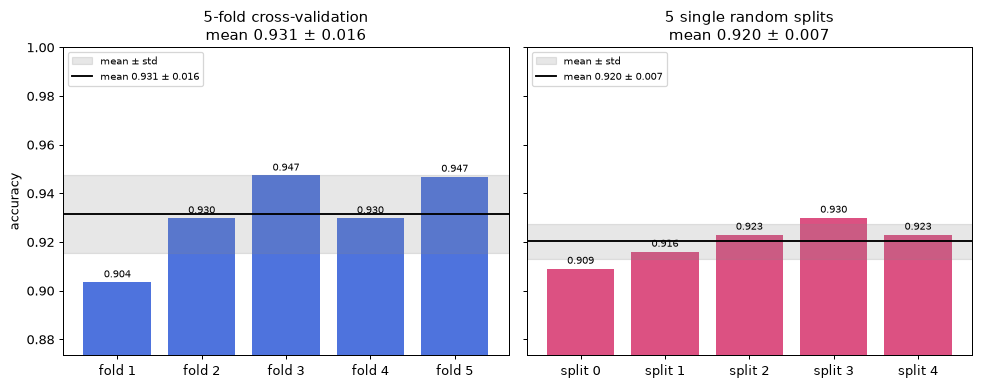

In [5]:
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 90
plt.rcParams['axes.grid'] = False
BLUE, PINK = '#2f5bd8', '#d6336c'
import matplotlib.pyplot as plt

single = []
for seed in range(5):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=seed)
    single.append(model.fit(Xtr, ytr).score(Xte, yte))
single = np.array(single)

lo = min(scores.min(), single.min()) - 0.03
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=True)
for ax, vals, labels, color, title in [
        (axes[0], scores, [f'fold {i + 1}' for i in range(len(scores))], BLUE, '5-fold cross-validation'),
        (axes[1], single, [f'split {i}' for i in range(len(single))], PINK, '5 single random splits')]:
    bars = ax.bar(labels, vals, color=color, alpha=0.85)
    ax.bar_label(bars, labels=[f'{v:.3f}' for v in vals], padding=2, fontsize=8)
    m, s = vals.mean(), vals.std()
    ax.axhspan(m - s, m + s, color='#888888', alpha=0.2, label='mean ± std')
    ax.axhline(m, color='black', linewidth=1.5, label=f'mean {m:.3f} ± {s:.3f}')
    ax.set_title(f'{title}\nmean {m:.3f} ± {s:.3f}')
    ax.set_ylim(lo, 1.0)
    ax.legend(loc='upper left', fontsize=8)
axes[0].set_ylabel('accuracy')
fig.tight_layout()
plt.show()
